# Supervised models

Notebook 02 showed that the data are a collection of studies, and that the usual random cross-validation partly
measures how well a model recognises a study. This notebook starts with the question that decides how to read every
later score: **how much does a model beat a trivial predictor on a study it has never seen, and is it the same for
every study?** Only then does it compare models.

Protocols, always on identical folds (`src.evaluation`): `random` (shuffled, stratified), `grouped` (5 folds of whole
studies) and `loso` (one study held out at a time, studies with at least 20 rows). Two scores are reported:
**R2**, which compares with the mean of the *test* fold (a value nobody knows beforehand), and **skill**
= 1 - SSE(model) / SSE(mean of the training fold), which is exactly 0 for a model that predicts the training mean
and positive when it does better.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")
PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "src" / "config.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

from src.baselines import baseline_models
from src.cleaning import clean_dataframe
from src.config import FIGURES_DIR, RESULTS_DIR, SCALED_CLIP, TARGETS
from src.evaluation import ALL_PROTOCOLS, ModelSpec, compare_models, per_study_scores, summarize, make_folds
from src.loading import load_raw
from src.models import GroupTunedRidge
from src.preprocessing import build_preprocessor, feature_spec

FIG = FIGURES_DIR / "supervised_models"
FIG.mkdir(parents=True, exist_ok=True)
OUT = RESULTS_DIR / "supervised_models"
OUT.mkdir(parents=True, exist_ok=True)

clean = clean_dataframe(load_raw())
print(clean.shape, "| studies held out one at a time:", len(make_folds(clean, "loso")))

(1652, 60) | studies held out one at a time: 15


## 1. Baselines and per-study scores

### 1.1 Reference scores under the three protocols

Two baselines (`src.baselines`): the **global mean** of the training fold, and the **study mean** (the mean of the
same study seen in training; on a study that was held out it can only fall back to the global mean). Two models: a
random forest and a ridge regression, the latter in two versions: the first one as it was before a defect was found
(scaled features unbounded, fixed penalty, see 1.4) and the corrected one (features clipped, penalty chosen by cross-validation
over whole studies inside the training data).

In [2]:
models = baseline_models() + [
    ModelSpec("ridge, no clip (before the fix)", "linear", lambda: Ridge(alpha=1.0), clip=None),
    ModelSpec("ridge, clipped, penalty tuned by study CV", "linear", GroupTunedRidge, uses_source=True),
    ModelSpec("random forest", "tree", lambda: RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)),
]
results = compare_models(clean, models, protocols=ALL_PROTOCOLS)
results.to_csv(OUT / "03_baselines_folds.csv", index=False)
summary = summarize(results)
summary.to_csv(OUT / "03_baselines_summary.csv", index=False)

order = [m.name for m in models]
for metric in ("skill_mean", "r2_mean"):
    table = summary.pivot_table(index=["target", "model"], columns="protocol", values=metric)
    table = table[["random", "grouped", "loso"]].reindex(order, level="model")
    print(f"\n{metric} (mean over folds; loso = mean over held-out studies)")
    print(table.round(2).to_string())


skill_mean (mean over folds; loso = mean over held-out studies)
protocol                                                         random  grouped  loso
target                model                                                           
charpy_toughness_j    global_mean                                  0.00     0.00  0.00
                      study_mean                                   0.20     0.00  0.00
                      ridge, no clip (before the fix)              0.60    -0.62 -2.46
                      ridge, clipped, penalty tuned by study CV    0.54    -0.22 -0.02
                      random forest                                0.83     0.16  0.22
elongation_pct        global_mean                                  0.00     0.00  0.00
                      study_mean                                   0.30     0.00  0.00
                      ridge, no clip (before the fix)              0.66    -0.44 -1.47
                      ridge, clipped, penalty tuned by study CV  

**Your conclusions:**

- **R2 on an unseen study mostly measures the study's offset.** The training-mean predictor, which learns nothing, scores R2 = -0.37 on yield strength and UTS, -0.68 on elongation, -0.70 on reduction of area and -0.65 on Charpy toughness in the grouped protocol, and down to -2.8 for the ductility targets when one study is held out. A forest at R2 = 0.05 on yield strength is therefore well above the trivial predictor. (My earlier reading of the smoke test, "R2 close to 0 means almost nothing is explained on a new study", was wrong: it had no reference point.)
- **Against the training mean, the forest has a modest but real skill on unseen studies**: yield strength 0.28 (grouped) / 0.30 (leave-one-study-out), UTS 0.42 / 0.39, Charpy toughness 0.16 / 0.22, reduction of area 0.29 / 0.09, elongation 0.28 / -0.06. Strength is the most predictable; elongation is not reliably better than the mean once a single study is held out.
- **The random protocol is far more flattering**: the forest's skill is 0.74-0.86 there, against 0.16-0.42 on unseen studies.
- **The ridge, before the fix, is worse than the mean on unseen studies** (skill between -0.62 and -2.46 on yield strength, UTS and Charpy depending on the protocol): this came from the preprocessing, see 1.4.
- **After the fix (features clipped, penalty chosen by cross-validation over studies inside the training data), the ridge is about as good as the mean**: yield strength 0.02 (grouped) / 0.01 (leave-one-study-out), UTS 0.34 / 0.15, Charpy -0.22 / -0.02, elongation -0.01 / -0.38, reduction of area 0.48 / -0.23. In leave-one-study-out it stays below the forest on every target. The grouped score for reduction of area (0.48, above the forest's 0.29) against -0.23 when studies are held out one at a time shows how much the 5-fold grouped protocol depends on which studies share a fold.


### 1.2 How much of the random score is only the study?

In [3]:
random_skill = summary[summary["protocol"] == "random"].pivot_table(index="target", columns="model", values="skill_mean")
share = pd.DataFrame({
    "study_mean": random_skill["study_mean"],
    "random_forest": random_skill["random forest"],
    "share_of_forest_skill_%": (100 * random_skill["study_mean"] / random_skill["random forest"]).round(0),
}).round(2)
share.to_csv(OUT / "03_study_share_of_random_skill.csv")
print("random protocol, skill:")
print(share.to_string())

random protocol, skill:
                       study_mean  random_forest  share_of_forest_skill_%
target                                                                   
charpy_toughness_j           0.20           0.83                     25.0
elongation_pct               0.30           0.74                     40.0
reduction_of_area_pct        0.55           0.74                     74.0
uts_mpa                      0.35           0.86                     41.0
yield_strength_mpa           0.35           0.82                     43.0


**Your conclusions:**

- **Knowing only the study already gives a large part of the random score**: the study-mean predictor has a skill of 0.35 on yield strength and UTS, 0.30 on elongation, 0.55 on reduction of area and 0.20 on Charpy toughness.
- **As a share of the forest's random skill** that is 43% (yield strength), 41% (UTS), 40% (elongation), 74% (reduction of area) and 25% (Charpy). For reduction of area, the random score mostly says "which study"; for the others it is under half. The rest of the forest's random skill (0.74-0.86) comes from rows of the same study that look alike, including the replicated inputs measured in notebook 02.
- **Consequence**: random-protocol scores should not be the headline; the study-held-out scores are the ones that carry information about a new study.

### 1.3 One score per held-out study

Each study is held out in turn, the model is trained on all the others and scored on it. `skill` is the error
reduction against the training mean, `bias` the mean error (a wrong *level* for the study) and `within_rho` the
Spearman correlation between prediction and truth inside the study (does the model follow the variations of a
study it has never seen, whatever its error on the level?).

rows scored per study and target:
target       yield_strength_mpa  uts_mpa  elongation_pct  reduction_of_area_pct  charpy_toughness_j
study                                                                                              
Cunh                         32       32              31                     32                   0
Evans                       331      331             330                    331                 437
EvansLetter                  52       52              51                     52                 104
Gar&K                        66       40              62                     61                   0
KocakPREv                    21       21              21                     21                   0
Mart                          0        0               0                      0                  63
Pat                           0        0               0                      0                  63
RR82011                      45       46              46          

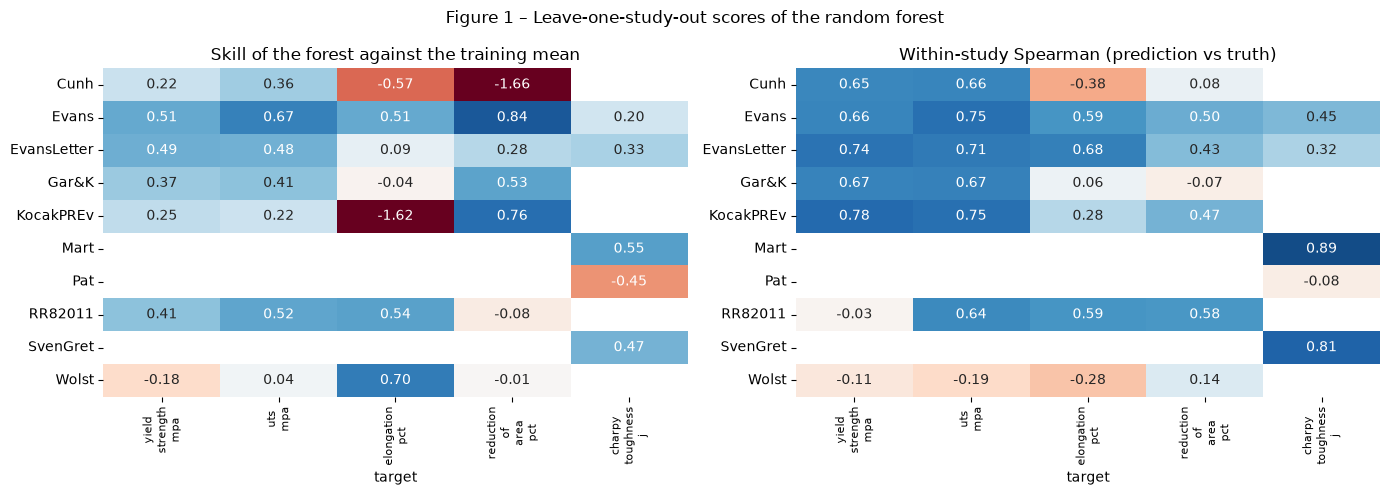

In [4]:
per_study = per_study_scores(results)
per_study.to_csv(OUT / "03_loso_scores.csv", index=False)
forest = per_study[per_study["model"] == "random forest"]
mean_model = per_study[per_study["model"] == "global_mean"]

skill = forest.pivot(index="study", columns="target", values="skill")[TARGETS]
rho = forest.pivot(index="study", columns="target", values="within_rho")[TARGETS]
n_rows = forest.pivot(index="study", columns="target", values="n_test")[TARGETS]
print("rows scored per study and target:")
print(n_rows.fillna(0).astype(int).to_string())
print("\nstudies where the forest beats the training mean (skill > 0), per target:")
print(((skill > 0).sum().astype(str) + " of " + skill.notna().sum().astype(str)).to_string())

bias = pd.DataFrame({"|bias| forest": forest.groupby("target")["bias"].apply(lambda s: s.abs().mean()),
                     "|bias| training mean": mean_model.groupby("target")["bias"].apply(lambda s: s.abs().mean())}).round(1)
print("\nmean |bias| over held-out studies:")
print(bias.loc[TARGETS].to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(skill, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Skill of the forest against the training mean")
sns.heatmap(rho, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Within-study Spearman (prediction vs truth)")
for ax in axes:
    ax.set_xticklabels([t.replace("_", "\n") for t in TARGETS], fontsize=8)
    ax.set_ylabel("")
fig.suptitle("Figure 1 \u2013 Leave-one-study-out scores of the random forest")
plt.tight_layout()
fig.savefig(FIG / "fig01_loso_skill_and_within_rho.png", dpi=150)
plt.show()

**Your conclusions:**

- **Strength transfers to unseen studies.** The forest beats the training mean on 6 of 7 studies for yield strength (skill 0.22-0.51; only Wolst, -0.18) and on 7 of 7 for UTS (0.04-0.67). Its mean level error is also smaller than that of the training mean: |bias| 25 vs 37 MPa (yield strength) and 26 vs 40 MPa (UTS).
- **It follows the variations inside a study it has never seen**: the within-study Spearman is 0.65-0.78 in five of the seven studies for yield strength and 0.64-0.75 in six of seven for UTS (medians 0.66 and 0.67). The failures are `Wolst` (-0.11 / -0.19; 23 rows) and `RR82011` on yield strength only (-0.03, while its UTS is 0.64).
- **Ductility is less reliable.** Elongation beats the mean in 4 of 7 studies (`Cunh` -0.57, `KocakPREv` -1.62, `Gar&K` -0.04 do not) with a median within-study Spearman of 0.28; reduction of area also in 4 of 7 (`Cunh` -1.66) with a median of 0.43. Part of the negative values comes from studies with a narrow spread (elongation in `KocakPREv` has a standard deviation of 1.8), where the training mean is already close and any error looks large.
- **Charpy toughness**: 4 of 5 studies positive (`Mart` 0.55, `SvenGret` 0.47, `EvansLetter` 0.33, `Evans` 0.20), `Pat` -0.45 (within-study Spearman -0.08). Only five studies, and the test temperature is a feature.
- **`Evans` (42% of the rows) is well predicted on every target** (0.51, 0.67, 0.51, 0.84, 0.20), so any average weighted by rows is dominated by it; this per-study table weights every study equally.
- **Caveats**: studies of 21-32 rows give noisy scores; the explanation of why `Wolst` or `Cunh` fail is not established and they should be inspected before any conclusion about measurement protocols.

### 1.4 Why the first ridge was worse than the mean

In [5]:
spec = feature_spec(clean, "yield_strength_mpa")
X, y = clean[spec.columns], clean["yield_strength_mpa"]
labeled = y.notna().to_numpy()
studies = sorted(clean["source"].value_counts()[lambda s: s >= 20].index)
rows = []
for study, (train, test) in zip(studies, make_folds(clean, "loso")):
    train, test = train[labeled[train]], test[labeled[test]]
    if len(test) < 20:
        continue
    pre = build_preprocessor("linear", spec, clip=None).fit(X.iloc[train])      # as before the fix
    held_out = pre.transform(X.iloc[test]).abs().max().sort_values(ascending=False)
    rows.append({"held-out study": study, "largest |scaled value| in training": round(pre.transform(X.iloc[train]).abs().max().max()),
                 "largest on the held-out study": round(held_out.iloc[0]), "column": held_out.index[0]})
print(f"Without the clip (the bound is now {SCALED_CLIP:g}):")
print(pd.DataFrame(rows).to_string(index=False))

linear = per_study[per_study["model"].str.startswith("ridge")]
effect = linear.groupby(["target", "model"])["skill"].agg(mean_skill="mean", share_positive=lambda s: (s > 0).mean()).round(2)
print("\nleave-one-study-out skill of the two ridge versions:")
print(effect.to_string())

Without the clip (the bound is now 5):
held-out study  largest |scaled value| in training  largest on the held-out study           column
          Cunh                                 995                            195      nb_conc_ppm
         Evans                                 170                            119       cr_conc_wt
   EvansLetter                                 950                             48      nb_conc_ppm
         Gar&K                                1198                            608        v_conc_wt
     KocakPREv                                1162                            162      ti_conc_ppm
       RR82011                                 960                            100 interpass_temp_c
         Wolst                                 860                            100 interpass_temp_c

leave-one-study-out skill of the two ridge versions:
                                                                 mean_skill  share_positive
target                m

**Your conclusions:**

- **The scaled features reached hundreds or thousands.** `RobustScaler` divides by the interquartile range of the median-filled column. For variables that are missing in more than half the rows (Nb, Sb, Cr) or concentrated on one value (interpass temperature, 64% of rows at 200 C) that range is zero, scikit-learn then divides by 1, and the variable stays in its raw unit. The largest scaled value was 170-1198 on the training rows and still 48-608 on a held-out study (V in `Gar&K` 608, Nb in `Cunh` 195, Ti in `KocakPREv` 162, Cr in `Evans` 119). A ridge extrapolates wildly on such values.
- **Fix applied in `src`**: the linear preprocessor clips the scaled numeric features to [-5, 5] (`SCALED_CLIP`), and `GroupTunedRidge` chooses the penalty among 1, 10, 100 and 1000 by cross-validation over whole studies of the training rows, so the scored study never takes part in the choice.
- **Leave-one-study-out skill, before -> after**: yield strength -1.69 -> +0.01, UTS -0.69 -> +0.15, elongation -1.47 -> -0.38, reduction of area -1.62 -> -0.23, Charpy -2.46 -> -0.02. The defect is gone (the ridge no longer extrapolates wildly), but a linear model brings little on a new study: about the mean for yield strength and Charpy, a modest gain for UTS, still below the mean for the ductility targets.
- **On the earlier figure**: a manual search over four settings on the scored studies gave +0.09 on yield strength; with the penalty chosen inside the training data it is +0.01. The first number was optimistic, as flagged at the time.
- **Tested but not adopted**: filling by scaling first then using 0, and dropping the poorly reported variables to avoid any NaN. The first gives no gain; the second hurts yield strength and UTS (the alloy elements carry the transferable signal) and helps only reduction of area and Charpy on 4 studies.


## 2. Ablations of the feature set

Before comparing a zoo of models, the feature set is fixed once, on two reference models (random forest, study-tuned ridge),
by changing one thing at a time against the baseline of section 1 (plan: `doc/04_ablation_plan.md`, code: `src/ablation.py`).

**Decision rule** (agreed): a variant is paired with the baseline on each held-out study (leave-one-study-out). It **helps** if its
mean skill gain is at least 0.05 and it wins on at least 2/3 of the (target, study) pairs, it **hurts** symmetrically, otherwise it is a **tie**.
The four tensile targets are pooled (27 pairs); Charpy toughness is read on its own (5 studies). The pair (`Cunh`, reduction of area) is left out:
its skill has a tiny denominator (notebook 03 diagnosis, `EXCLUDED_FROM_JUDGMENT`). The `grouped` protocol, repeated on 5 seeds, and `random` are context, never a ranking.

mean skill gain against the baseline, leave-one-study-out (share of pairs won); rule: gain >= 0.05, wins >= 67%
algo                   random forest                            ridge                   
scope             charpy_toughness_j       tensile charpy_toughness_j            tensile
variant                                                                                 
no_missing_flags        -0.00  (40%)  +0.00  (48%)       -0.01  (60%)       -0.07  (41%)
no_censored_flags       -0.00  (60%)  +0.01  (63%)       -0.01  (20%)       -0.00  (74%)
no_flags                +0.00  (40%)  +0.01  (67%)       -0.05  (60%)       -0.05  (41%)
drop_mo                 +0.04  (20%)  -0.02  (37%)       -0.00  (40%)       -0.04  (30%)
drop_arc                -0.00  (40%)  -0.03  (37%)       +0.01  (60%)  +0.06 helps (81%)
study_weights           +0.07  (60%)  -0.00  (44%)  -0.20 hurts (20%)       -0.04  (44%)
pca6                    +0.07  (40%)  -0.00  (41%)       -0.00  (40%)       -0.01  (41%

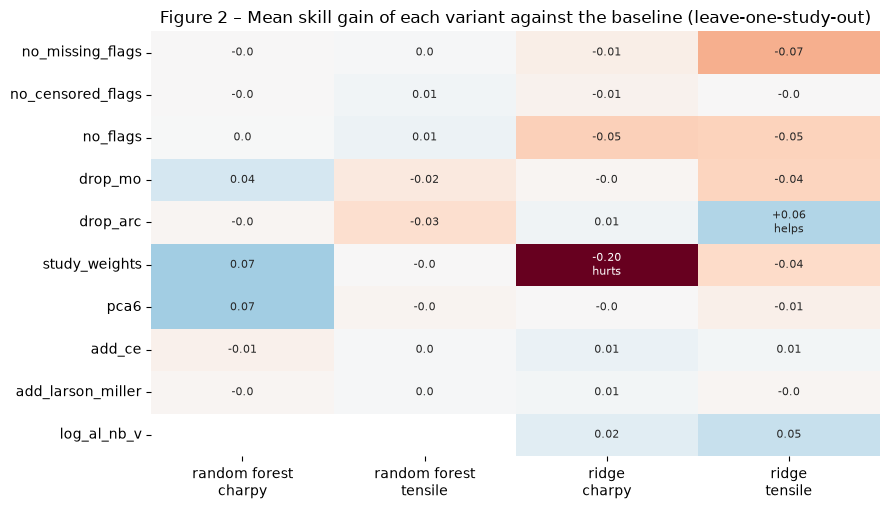

In [6]:
from src.ablation import VARIANTS, decision_table, grouped_seed_spread, loso_deltas, run_ablation
from src.config import MIN_SKILL_GAIN, MIN_WIN_SHARE

ablation = run_ablation(clean)                      # about 7 minutes
ablation.to_csv(OUT / "03_ablation_folds.csv", index=False)
decisions = decision_table(ablation)
decisions.to_csv(OUT / "03_ablation_decisions.csv", index=False)

order = [v for v in VARIANTS if v != "baseline"]
columns = ["algo", "scope"]
gain = decisions.pivot_table(index="variant", columns=columns, values="mean_skill_gain").reindex(order)
verdict = decisions.pivot_table(index="variant", columns=columns, values="verdict", aggfunc="first").reindex(order)
wins = decisions.pivot_table(index="variant", columns=columns, values="win_share").reindex(order)
shown = gain.round(2).map(lambda v: "" if pd.isna(v) else f"{v:+.2f}") + " " + verdict.fillna("").replace("tie", "") + \
        wins.map(lambda v: "" if pd.isna(v) else f" ({v:.0%})")
print(f"mean skill gain against the baseline, leave-one-study-out (share of pairs won); rule: gain >= {MIN_SKILL_GAIN}, wins >= {MIN_WIN_SHARE:.0%}")
print(shown.to_string())
print("\nverdicts:", decisions["verdict"].value_counts().to_dict(), "out of", len(decisions), "comparisons")

fig, ax = plt.subplots(figsize=(9, 5.2))
flat = gain.copy(); flat.columns = [f"{a}\n{s.replace('_toughness_j', '')}" for a, s in flat.columns]
labels = flat.round(2).astype(str)
for (a, s) in gain.columns:
    name = f"{a}\n{s.replace('_toughness_j', '')}"
    for v in order:
        if verdict.loc[v, (a, s)] in ("helps", "hurts"):
            labels.loc[v, name] = f"{gain.loc[v, (a, s)]:+.2f}\n{verdict.loc[v, (a, s)]}"
sns.heatmap(flat, annot=labels, fmt="", cmap="RdBu", center=0, vmin=-0.2, vmax=0.2, cbar=False, ax=ax, annot_kws={"fontsize": 8})
ax.set_ylabel(""); ax.set_xlabel("")
ax.set_title("Figure 2 \u2013 Mean skill gain of each variant against the baseline (leave-one-study-out)")
plt.tight_layout(); fig.savefig(FIG / "fig02_ablation_skill_gain.png", dpi=150); plt.show()

**Your conclusions:**

- **36 of the 38 comparisons are ties; none helps the forest.** The only two verdicts: the ridge **without current, voltage and heat input** helps on the tensile targets (+0.06, 81% of the pairs won), and the ridge **with study weights** hurts Charpy toughness (-0.20, 20% won: `EvansLetter` -0.48, `Mart` -0.37). With 38 comparisons at this threshold, one "helps" can come by chance (2.3 below).
- **The ties are expected, not a failure of the rule.** The skill of the 5-fold grouped protocol moves by 0.03-0.16 from one seed to the next (UTS 0.16, Charpy 0.12): a gain of 0.05 is the size of the noise, which is why the rule asks for wins on two thirds of the studies as well.
- **Nothing that adds information helps.** PCA scores (-0.00 forest, -0.01 ridge on the tensile targets), carbon equivalent (+0.00 / +0.01), Larson-Miller parameter (+0.00 / -0.00) and the shifted log on Al, Nb, V for the ridge (+0.05, but only 52% of the pairs won) are ties. Two caveats: the carbon equivalent exists on only 418 rows (25%) because a missing element is not zero, and the Larson-Miller parameter adds nothing a tree cannot already get from the PWHT temperature and time.
- **Study weights do not help a new study**: no effect on the tensile targets (-0.00 forest, -0.04 ridge) and a clear loss for the ridge on Charpy toughness.


### 2.1 Do the missing / censored flags help on a study already seen, and not on a new one?

In [7]:
flags = decisions[decisions["variant"].isin(["no_missing_flags", "no_censored_flags", "no_flags"]) & (decisions["scope"] == "tensile")]
table = flags.set_index(["algo", "variant"])[["gain_random", "gain_grouped", "mean_skill_gain", "win_share"]]
table.columns = ["random", "grouped", "leave-one-study-out", "share won (loso)"]
print("skill change when the flags are REMOVED, four tensile targets pooled:")
print(table.round(2).to_string())

skill change when the flags are REMOVED, four tensile targets pooled:
                                 random  grouped  leave-one-study-out  share won (loso)
algo          variant                                                                  
random forest no_missing_flags     0.00     0.00                 0.00              0.48
              no_censored_flags    0.00     0.00                 0.01              0.63
              no_flags             0.00     0.00                 0.01              0.67
ridge         no_missing_flags    -0.03    -0.04                -0.07              0.41
              no_censored_flags   -0.00    -0.01                -0.00              0.74
              no_flags            -0.02    -0.04                -0.05              0.41


**Your conclusions:**

- **The idea that the flags are study fingerprints that help a seen study and not a new one is not supported.** For the forest, removing the missing and censored flags changes the skill by 0.00-0.01 under every protocol: a tree keeps the NaN and can split on them, so the flags say nothing it cannot read already.
- **For the ridge, the missing flags carry real information** that the median fill erases: removing them costs 0.03 (random), 0.04 (grouped) and 0.07 (leave-one-study-out). The loss is *larger* on a new study than on a seen one, which is the opposite of study recognition. The verdict is still a tie, because removing them wins on 41% of the pairs and the loss is not spread over two thirds of them. The censored flags change nothing (|gain| <= 0.01).


### 2.2 Molybdenum, study by study

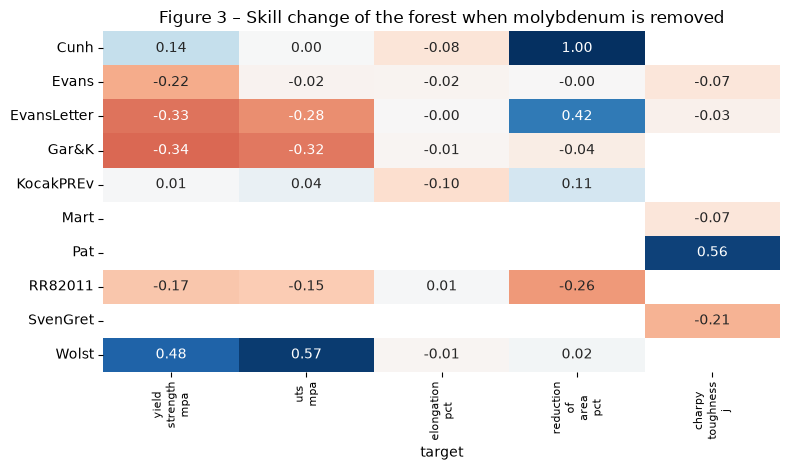

studies x targets that improve / get worse without Mo: 12 / 21


In [8]:
delta_mo = loso_deltas(ablation, "random forest", "drop_mo")
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(delta_mo, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-0.6, vmax=0.6, cbar=False, ax=ax)
ax.set_xticklabels([t.replace("_", "\n") for t in delta_mo.columns], fontsize=8); ax.set_ylabel("")
ax.set_title("Figure 3 \u2013 Skill change of the forest when molybdenum is removed")
plt.tight_layout(); fig.savefig(FIG / "fig03_drop_mo_per_study.png", dpi=150); plt.show()
print("studies x targets that improve / get worse without Mo:", int((delta_mo > 0).sum().sum()), "/", int((delta_mo < 0).sum().sum()))

**Your conclusions:**

- **The diagnosis of the failures is confirmed, and it is not a fix.** Without Mo, `Wolst` improves a lot (UTS +0.57, yield strength +0.48), as does `Pat` on Charpy (+0.56) and `Cunh` on reduction of area (+1.00, a pair left out of the rule). But 21 of the 33 study-target pairs get worse: `Evans` yield strength -0.22, `EvansLetter` -0.33 (yield) and -0.28 (UTS), `Gar&K` -0.34 and -0.32, `RR82011` -0.17, `SvenGret` Charpy -0.21.
- **Reading**: Mo is a real strengthening signal in the alloyed studies where it varies inside the range seen in training, and misleading on a study whose Mo is out of that range or whose relation has the opposite sign (`Wolst`, `Pat`). Pooled, the effect is a tie on the tensile targets (-0.02, 37% of the pairs won) and on Charpy (+0.04 on average but won on one study of five, `Pat`). Mo stays in; any recommendation involving Mo has to be checked study by study.
- **The diagnosis itself** (done by a helper agent on scikit-learn 1.5, scripts outside the repository, not reproduced here) is summarised in `doc/03_project_structure.md`.


### 2.3 Arc variables, and how much of a gain is noise

In [9]:
spread = grouped_seed_spread(ablation)
print("baseline, 5-fold grouped protocol repeated on 5 seeds: mean and standard deviation over seeds of the skill")
print(spread.round(2).to_string())

tensile = ["yield_strength_mpa", "uts_mpa", "elongation_pct", "reduction_of_area_pct"]
part = ablation[(ablation["protocol"] == "grouped") & (ablation["algo"] == "ridge") & ablation["variant"].isin(["baseline", "drop_arc"])
                & ablation["target"].isin(tensile)]
per_seed = part.groupby(["variant", "seed"])["skill"].mean().unstack("variant")
per_seed["gain"] = per_seed["drop_arc"] - per_seed["baseline"]
print("\nridge without current / voltage / heat input, grouped protocol, tensile targets, per seed:")
print(per_seed.round(3).to_string())
print("\nleave-one-study-out, ridge, skill change without the arc variables:")
print(loso_deltas(ablation, "ridge", "drop_arc").round(2).to_string())

baseline, 5-fold grouped protocol repeated on 5 seeds: mean and standard deviation over seeds of the skill
                                     skill_mean  skill_std
algo          target                                      
random forest charpy_toughness_j           0.01       0.12
              elongation_pct               0.33       0.03
              reduction_of_area_pct        0.22       0.08
              uts_mpa                      0.29       0.16
              yield_strength_mpa           0.31       0.05
ridge         charpy_toughness_j          -0.15       0.15
              elongation_pct               0.02       0.10
              reduction_of_area_pct        0.38       0.12
              uts_mpa                      0.26       0.14
              yield_strength_mpa           0.06       0.08

ridge without current / voltage / heat input, grouped protocol, tensile targets, per seed:
variant  baseline  drop_arc   gain
seed                              
0           0.208     0

**Your conclusions:**

- **Noise floor**: the standard deviation over seeds of the baseline skill is, for the forest, 0.03-0.05 for yield strength and elongation, 0.08 for reduction of area, 0.12-0.16 for UTS and Charpy; for the ridge, 0.08-0.15. Differences below these values between two grouped scores say nothing.
- **Arc variables and the ridge**: removing them gains +0.06 in leave-one-study-out, with small gains in most studies (`Evans` +0.01 to +0.05 on three tensile targets but -0.10 on reduction of area and -0.12 on Charpy, `Gar&K` +0.01 to +0.08, `RR82011`, `Wolst`) and large swings on two small ones (`Cunh` UTS +0.52, `KocakPREv` UTS +0.43 but yield strength -0.34). In the grouped protocol the gain is +0.09, +0.06, -0.06, +0.01, +0.05 over the five seeds (mean +0.03, positive in four). It is coherent with these variables being study identifiers (89-98% study, notebook 02) that a linear model uses as offsets, but the evidence is modest. For the forest the effect is -0.03 (a tie), so it is **not** applied to the common feature set; it stays an option to test on the other linear models of the zoo.


### 2.4 What is kept

**The feature set of the zoo is the baseline** (`doc/01`): the 25 numeric features, the three categoricals, the `_missing` and `_censored` flags, no PCA scores, no derived feature, no study weights, Mo and arc variables kept.

| Variant | Verdict | Decision |
|---|---|---|
| flags (missing, censored, both) | tie (forest 0.00-0.01); ridge loses 0.05-0.07 without the missing flags | keep |
| `drop_mo` | tie, mechanism of the failures confirmed | keep Mo, read it study by study |
| `drop_arc` | helps the ridge (+0.06), tie for the forest (-0.03) | keep in the common set; **option for the linear models of the zoo** |
| `study_weights` | hurts the ridge on Charpy, tie elsewhere | not applied |
| `pca6`, `add_ce`, `add_larson_miller`, `log_al_nb_v` | ties | not applied |

**A change to the written plan (agreed)**: `doc/04_ablation_plan.md` said that a tie keeps the simpler setting (the variant that removes something). Applied here it would remove the missing flags (forest tie), Mo and the arc variables, against the evidence above. The rule is now: **a tie keeps the baseline**, and only a verdict "helps" changes the feature set.


## 3. Model zoo

Option 1 of the plan: classical regressors, each tuned by a **small grid with cross-validation over whole studies inside the training fold** (`src/models.py::GroupTunedSearch`, grids in `src/zoo.py`), then judged in leave-one-study-out with the rule of section 2 (gain >= 0.05 and wins on >= 2/3 of the (target, study) pairs; a tie keeps the reference). The retained models are then checked on the `grouped` protocol repeated on 5 seeds.

- **Linear family** (median fill, scaling, clip): Lasso, ElasticNet, k-NN, SVR with an RBF kernel, each also **without current, voltage and heat input** (`+ drop_arc`, section 2.3).
- **Tree family** (NaN kept): ExtraTrees, the random forest **tuned** with the same kind of grid, and three boostings (scikit-learn's histogram gradient boosting, XGBoost, CatBoost) compared in 3.4.
- **References**: the random forest of section 1 (200 trees, not tuned), the study-tuned ridge, and the two trivial predictors. The tuned forest is added as a third reference because the first one is not tuned: it shows how much of a candidate's gain is only tuning.

The targets are standardised before the search (the penalty of a Lasso and the epsilon of an SVR depend on their scale). Tuned and judged on the same 5-7 studies per target, so a gain proves a mechanism, it is not a number to claim.

### 3.1 Leave-one-study-out scores and the decision against each reference

In [2]:
from src.config import EXCLUDED_FROM_JUDGMENT, MIN_SKILL_GAIN, MIN_WIN_SHARE, TENSILE_TARGETS
from src.zoo import DECISION_REFERENCES, grouped_summary, pooled_loso_skill, retained, run_option_one, zoo_decisions

RERUN_ZOO = False      # True recomputes everything (about 45 minutes); False reuses the saved tables and computes only the missing models
zoo_loso, zoo_grouped = run_option_one(clean, OUT, rerun=RERUN_ZOO, log=print)
zoo_all = pd.concat([zoo_decisions(zoo_loso, ref) for ref in DECISION_REFERENCES], ignore_index=True)
zoo_all.to_csv(OUT / "03_zoo_decisions.csv", index=False)
grouped_summary(zoo_grouped).to_csv(OUT / "03_zoo_grouped_summary.csv", index=False)

judged = zoo_loso[[(s, t) not in EXCLUDED_FROM_JUDGMENT for s, t in zip(zoo_loso["study"], zoo_loso["target"])]]
tensile = judged[judged["target"].isin(TENSILE_TARGETS)]
charpy = judged[judged["target"] == "charpy_toughness_j"]
overview = pd.DataFrame({
    "skill tensile": tensile.groupby("model")["skill"].mean(),
    "within_rho tensile": tensile.groupby("model")["within_rho"].mean(),
    "|bias| tensile": tensile.groupby("model")["bias"].apply(lambda s: s.abs().mean()),
    "skill Charpy": charpy.groupby("model")["skill"].mean(),
    "within_rho Charpy": charpy.groupby("model")["within_rho"].mean(),
}).sort_values("skill tensile", ascending=False).round(2)
print("leave-one-study-out, mean over the (target, study) pairs (the pair Cunh / reduction of area is left out):")
print(overview.to_string())

for ref in DECISION_REFERENCES:
    part = zoo_all[(zoo_all["reference"] == ref) & ~zoo_all["model"].isin(["global_mean", "study_mean"])]
    gain = part.pivot_table(index="model", columns="scope", values="mean_skill_gain")
    wins = part.pivot_table(index="model", columns="scope", values="win_share")
    verdict = part.pivot_table(index="model", columns="scope", values="verdict", aggfunc="first")
    shown = gain.round(2).map(lambda v: f"{v:+.2f}") + " " + verdict.replace("tie", "") + wins.map(lambda v: f" ({v:.0%})")
    print(f"\nmean skill gain against '{ref}' (share of pairs won); rule: gain >= {MIN_SKILL_GAIN}, wins >= {MIN_WIN_SHARE:.0%}")
    print(shown.to_string())
print("\nverdicts:", zoo_all.groupby("reference")["verdict"].value_counts().unstack().fillna(0).astype(int).to_string(), sep="\n")

leave-one-study-out, mean over the (target, study) pairs (the pair Cunh / reduction of area is left out):
                        skill tensile  within_rho tensile  |bias| tensile  skill Charpy  within_rho Charpy
model                                                                                                     
catboost                         0.36                0.57           11.98          0.37               0.67
hist gradient boosting           0.33                0.50           13.42          0.31               0.56
random forest (tuned)            0.31                0.43           13.77          0.20               0.58
xgboost                          0.26                0.50           12.16          0.30               0.55
random forest                    0.25                0.41           14.48          0.22               0.48
extra trees                      0.10                0.42           20.97          0.21               0.63
elasticnet + drop_arc            0.09 

**Your conclusions:**

- **Only the forests and the boostings transfer to a new study, on average.** Mean leave-one-study-out skill on the four tensile targets: CatBoost 0.36, histogram boosting 0.33, tuned forest 0.31, XGBoost 0.26, forest 0.25, ExtraTrees 0.10, then the linear family and the SVR at 0.01-0.09, and k-NN below the training mean (-0.39 and -0.48).
- **Tuning alone is worth +0.06.** The tuned forest beats the untuned one (helps, 70% of the pairs). The reference of the next comparisons is therefore the **tuned forest**, not the first one.
- **Against the tuned forest, only CatBoost wins on the tensile targets, and right at both thresholds** (+0.05, 18 of 27 pairs = two thirds). The histogram boosting (+0.02) and XGBoost (-0.05) are ties; the untuned forest is at -0.06 and every other model at -0.21 to -0.79, `hurts` for all of them except `svr rbf + drop_arc` (tie). On Charpy toughness the three boostings help (+0.17 CatBoost, +0.11 histogram, +0.10 XGBoost; 4 or 5 studies out of 5), on five studies only.
- **Against the untuned forest the boostings do better** (CatBoost +0.11 on 78% of the pairs, histogram +0.08 on exactly two thirds, XGBoost a tie), and the comparison with the tuned forest shows that part of it is tuning.
- **The linear models and the SVR fail on the level, not on the ranking.** Their mean |bias| on a new study is 21-24, that of the training mean (22.1), while the forests and the boostings are at 12.0-14.5. Their within-study rank correlation is as good as the forests' (0.42-0.46 against 0.41-0.43 for the forests and 0.50-0.57 for the boostings on the tensile targets; 0.67-0.71 against 0.48-0.67 for the trees on Charpy). They order the welds of a study, they do not set its level. Lasso, ElasticNet and the SVR are ties with the study-tuned ridge on the tensile targets (-0.04 to +0.05); ElasticNet beats it on Charpy (+0.23, 4 studies out of 5).
- **k-NN is the worst, with a within-study correlation of 0.26-0.28.** A likely reason (not tested): distances over 64 columns, many of them flags and dummies that identify the study.

### 3.2 Where the histogram boosting differs from the tuned forest

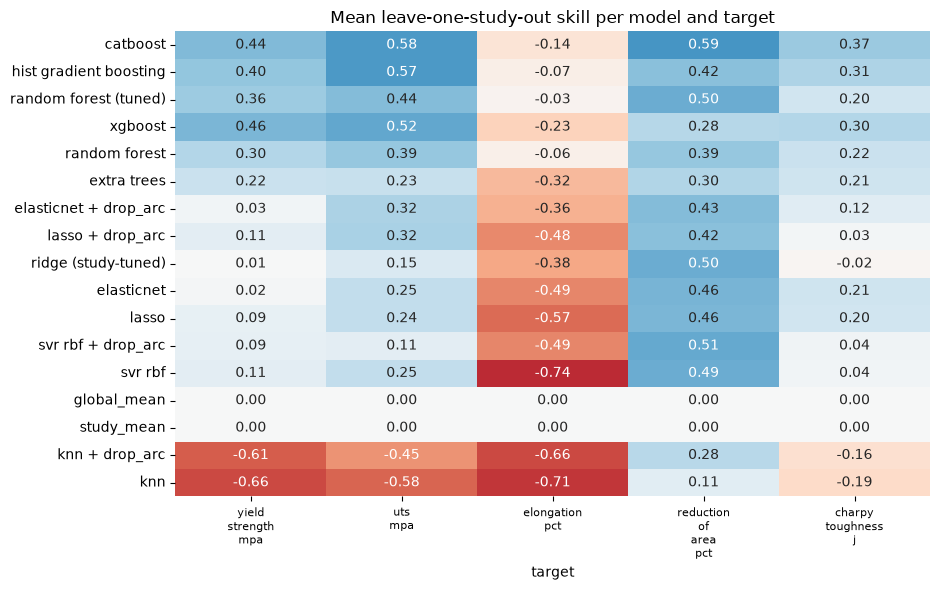

boosting minus tuned forest, mean over the held-out studies of each target:
                       mean   min   max  count
target                                        
yield_strength_mpa     0.03 -0.18  0.23      7
uts_mpa                0.14 -0.03  0.50      7
elongation_pct        -0.04 -0.26  0.15      7
reduction_of_area_pct -0.08 -0.39  0.01      6
charpy_toughness_j     0.11  0.01  0.26      5

largest gains and losses:
target                 study      
reduction_of_area_pct  Wolst         -0.39
elongation_pct         Wolst         -0.26
                       EvansLetter   -0.24
charpy_toughness_j     SvenGret       0.26
uts_mpa                Gar&K          0.26
                       Wolst          0.50


In [3]:
pooled = tensile.groupby(["model", "target"])["skill"].mean().unstack()[TENSILE_TARGETS]
pooled["charpy_toughness_j"] = charpy.groupby("model")["skill"].mean()
order = overview.index.tolist()
fig, ax = plt.subplots(figsize=(9.5, 6))
sns.heatmap(pooled.reindex(order), annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, cbar=False, ax=ax)
ax.set_title("Mean leave-one-study-out skill per model and target")
ax.set_xticklabels([t.replace("_", "\n") for t in pooled.columns], rotation=0, fontsize=8)
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG / "fig04_zoo_loso_skill.png", dpi=130)
plt.show()

pair = judged[judged["model"].isin(["hist gradient boosting", "random forest (tuned)"])].pivot_table(
    index=["target", "study"], columns="model", values="skill")
pair["gain"] = pair["hist gradient boosting"] - pair["random forest (tuned)"]
print("boosting minus tuned forest, mean over the held-out studies of each target:")
print(pair["gain"].groupby("target").agg(["mean", "min", "max", "count"]).round(2).reindex([*TENSILE_TARGETS, "charpy_toughness_j"]).to_string())
print("\nlargest gains and losses:")
print(pair["gain"].round(2).sort_values().iloc[[0, 1, 2, -3, -2, -1]].to_string())

**Your conclusions:**

- **The histogram boosting gains on UTS and loses on the ductility targets.** Against the tuned forest, the mean change over the held-out studies is +0.14 on UTS, +0.03 on yield strength, -0.04 on elongation and -0.08 on reduction of area (without `Cunh`). The pooled tie (+0.02) hides movements of opposite sign.
- **One study carries a large part of it.** `Wolst` goes from 0.07 to 0.58 on UTS (+0.50) and drops on reduction of area (-0.39) and elongation (-0.26); it is one of the two studies on which Mo misleads (section 2.2). Without it, the gains are +0.07 on yield strength, +0.08 on UTS, 0.00 on elongation and -0.02 on reduction of area (+0.03 pooled): a small gain on the strength targets, no loss on ductility.
- **Reading the heatmap.** On yield strength and UTS the forests and the boostings are the only rows clearly above 0 (0.22-0.58, against 0.01-0.32 for the linear family). **Elongation does not transfer to a new study for any model**: the random forests are at -0.03 to -0.07 (the training mean is as good; ExtraTrees -0.32), the boostings at -0.07 (histogram), -0.14 (CatBoost) and -0.23 (XGBoost), the linear family and the SVR at -0.36 to -0.74. **On reduction of area the linear models match the forests** (0.42-0.51 against 0.39-0.50; ridge and tuned forest are both at 0.50); only CatBoost is clearly above (0.59), XGBoost below (0.28). k-NN is negative on four targets out of five.

### 3.3 The retained models on the grouped protocol (5 seeds)

In [4]:
summary = grouped_summary(zoo_grouped)
mean = summary.pivot(index="model", columns="target", values="skill_mean")[TARGETS]
std = summary.pivot(index="model", columns="target", values="skill_std")[TARGETS]
shown = mean.round(2).astype(str) + " +/- " + std.round(2).astype(str)
print("retained for this check (top 3 candidates of 3.1 and the references):", retained(zoo_loso))
print("\ngrouped protocol, skill: mean +/- standard deviation over 5 seeds of the fold-mean skill")
print(shown.to_string())

retained for this check (top 3 candidates of 3.1 and the references): ['random forest', 'ridge (study-tuned)', 'catboost', 'hist gradient boosting', 'random forest (tuned)']

grouped protocol, skill: mean +/- standard deviation over 5 seeds of the fold-mean skill
target                 yield_strength_mpa        uts_mpa elongation_pct reduction_of_area_pct charpy_toughness_j
model                                                                                                           
catboost                    0.52 +/- 0.04   0.5 +/- 0.08  0.34 +/- 0.03         0.38 +/- 0.11      0.16 +/- 0.15
extra trees                 0.32 +/- 0.05  0.31 +/- 0.06  0.21 +/- 0.07         0.18 +/- 0.11      0.11 +/- 0.05
hist gradient boosting      0.47 +/- 0.05  0.49 +/- 0.11   0.3 +/- 0.07         0.24 +/- 0.11     -0.01 +/- 0.14
random forest               0.31 +/- 0.05  0.29 +/- 0.16  0.33 +/- 0.03         0.22 +/- 0.08      0.01 +/- 0.12
random forest (tuned)       0.32 +/- 0.04  0.29 +/- 0.18  

**Your conclusions:**

- **The three boostings beat the tuned forest on yield strength under the grouped protocol, by more than the noise**: CatBoost 0.52 +/- 0.04, histogram 0.47 +/- 0.05, XGBoost 0.46 +/- 0.02, against 0.32 +/- 0.04. On UTS, CatBoost (0.50 +/- 0.08) and the histogram boosting (0.49 +/- 0.11) are +0.20 above the forest (0.29 +/- 0.18), within the spread of the forest; XGBoost is at 0.42 +/- 0.19.
- **CatBoost is the highest or equal on every target**: elongation 0.34 (as the forest), reduction of area 0.38 against 0.32 (spread 0.07-0.11), Charpy toughness 0.16 +/- 0.15 against 0.04 +/- 0.08. The histogram boosting and XGBoost have no gain on elongation (0.30, 0.32), reduction of area (0.24, 0.24) or Charpy (-0.01, 0.01).
- **The tuned forest is at least as good as the untuned one on every target** (reduction of area 0.32 against 0.22, Charpy 0.04 against 0.01, the rest within 0.01), consistently with the +0.06 of 3.1.
- **ExtraTrees is not better than the forest** (elongation 0.21, reduction of area 0.18). **The study-tuned ridge is far below the trees on yield strength and elongation (0.06 and 0.02), but it is the best of the non-CatBoost models on reduction of area (0.38, the SVR 0.35, the tuned forest 0.32)**: the same exception as in 3.2.
- **The spread between seeds is 0.02-0.23**, the same order as most of the gains discussed: only the yield-strength gains of the boostings clearly stand out of it.

### 3.4 Three boosting libraries, same protocol

`hist gradient boosting` (scikit-learn), `xgboost` and `catboost` get **the same protocol**: the same folds, 8 configurations, a number of rounds fixed beforehand, NaN kept, tuned by cross-validation over studies inside the training fold. Each has its own regularisation knobs: XGBoost tunes the depth and the minimum hessian mass of a leaf and subsamples 80% of the rows and columns (150 rounds); CatBoost grows symmetric trees, weaker per round, so it gets 300 rounds and is tuned on depth and the L2 penalty. The grouped protocol (5 seeds) is run for the three.

In [5]:
boosters = ["catboost", "hist gradient boosting", "xgboost", "random forest (tuned)"]
by_target = judged[judged["model"].isin(boosters)].pivot_table(index="model", columns="target", values="skill").reindex(boosters)
by_target = by_target[[*TENSILE_TARGETS, "charpy_toughness_j"]]
by_study = tensile[tensile["model"].isin(boosters)].groupby(["model", "study"])["skill"].mean().unstack().reindex(boosters)
print("leave-one-study-out skill per target (mean over the held-out studies):")
print(by_target.round(2).to_string())
print("\nleave-one-study-out skill per held-out study (mean over the four tensile targets):")
print(by_study.round(2).to_string())

for ref in ("hist gradient boosting", "random forest (tuned)"):
    part = zoo_decisions(zoo_loso[zoo_loso["model"].isin(boosters)], ref)
    print(f"\nagainst '{ref}':")
    print(part[["model", "scope", "n_pairs", "mean_skill_gain", "win_share", "verdict"]].round(2).to_string(index=False))

pair = judged[judged["model"].isin(["catboost", "random forest (tuned)"])].pivot_table(index=["target", "study"], columns="model", values="skill")
pair["gain"] = pair["catboost"] - pair["random forest (tuned)"]
print("\ncatboost minus tuned forest, mean over the held-out studies of each target:")
print(pair["gain"].groupby("target").agg(["mean", "min", "max", "count"]).round(2).reindex([*TENSILE_TARGETS, "charpy_toughness_j"]).to_string())
print("\nstudies where catboost is below the tuned forest:", int((pair["gain"] < 0).sum()), "of", len(pair))
print(pair["gain"].round(2).sort_values().iloc[[0, 1, 2, -3, -2, -1]].to_string())

leave-one-study-out skill per target (mean over the held-out studies):
target                  yield_strength_mpa  uts_mpa  elongation_pct  reduction_of_area_pct  charpy_toughness_j
model                                                                                                         
catboost                              0.44     0.58           -0.14                   0.59                0.37
hist gradient boosting                0.40     0.57           -0.07                   0.42                0.31
xgboost                               0.46     0.52           -0.23                   0.28                0.30
random forest (tuned)                 0.36     0.44           -0.03                   0.50                0.20

leave-one-study-out skill per held-out study (mean over the four tensile targets):
study                   Cunh  Evans  EvansLetter  Gar&K  KocakPREv  RR82011  Wolst
model                                                                             
catboost     

**Your conclusions:**

- **CatBoost is the best of the three boostings in this protocol, XGBoost the weakest.** Mean leave-one-study-out skill on the tensile targets (3.1): CatBoost 0.36, histogram 0.33, XGBoost 0.26, tuned forest 0.31. Against the tuned forest, CatBoost helps on the tensile targets (+0.05 on 67% of the pairs, right at both thresholds) and on Charpy (+0.17, 4 studies out of 5); the histogram boosting and XGBoost are ties on the tensile targets (+0.02, -0.05). Against the histogram boosting, CatBoost is a tie on the tensile targets (+0.03, 63%) and helps on Charpy (+0.07, 4 studies out of 5).
- **Where CatBoost gains**: UTS +0.14 (it is above the tuned forest on all 7 studies, at least +0.07), reduction of area +0.09, yield strength +0.08, Charpy +0.17; it loses on elongation (-0.10). It is above the tuned forest on 5 studies out of 7 (mean of the four tensile targets: `Cunh` +0.19, `EvansLetter` +0.14, `RR82011` +0.17, `Gar&K` +0.12, `Evans` +0.09), and below on two, the ones that already fail with the other models: `KocakPREv` (-0.16 against 0.00; elongation -0.77) and `Wolst` (0.15 against 0.31; yield strength -0.60). It is below the forest on 10 of the 32 (target, study) pairs.
- **XGBoost** has the best mean yield strength (0.46) but loses on elongation (-0.23) and reduction of area (0.28 against 0.50 for the forest): no better than the forest overall.
- **What this does not settle.** The three boostings were tuned and judged on the same 5-7 studies; CatBoost's verdict sits exactly on the thresholds; and the two libraries do not share the same number of rounds (150 for the histogram boosting and XGBoost, 300 for CatBoost, fixed beforehand), so part of the gap may come from the rounds rather than from the library. A grid with the number of rounds chosen by cross-validation over studies would answer it.

### 3.5 Without current, voltage and heat input, for the linear models

In [6]:
rows = []
for name in ("lasso", "elasticnet", "knn", "svr rbf"):
    pair_table = zoo_decisions(zoo_loso[zoo_loso["model"].isin([name, f"{name} + drop_arc"])], name)
    rows.append(pair_table.assign(model=name))
arc = pd.concat(rows)[["model", "scope", "n_pairs", "mean_skill_gain", "win_share", "mean_rho_gain", "verdict"]]
print("skill change when current, voltage and heat input are removed (leave-one-study-out):")
print(arc.round(2).to_string(index=False))

skill change when current, voltage and heat input are removed (leave-one-study-out):
     model              scope  n_pairs  mean_skill_gain  win_share  mean_rho_gain verdict
     lasso            tensile       27             0.04       0.52           0.01     tie
     lasso charpy_toughness_j        5            -0.17       0.20          -0.00   hurts
elasticnet            tensile       27             0.05       0.56           0.02     tie
elasticnet charpy_toughness_j        5            -0.09       0.20          -0.02     tie
       knn            tensile       27             0.10       0.56           0.02     tie
       knn charpy_toughness_j        5             0.03       0.40           0.11     tie
   svr rbf            tensile       27             0.03       0.41           0.01     tie
   svr rbf charpy_toughness_j        5             0.01       0.20          -0.02     tie


**Your conclusions:**

- **Removing the arc variables never reaches a verdict on the tensile targets**: +0.04 (Lasso), +0.05 (ElasticNet), +0.10 (k-NN), +0.03 (SVR), winning on 41-56% of the pairs, below the two thirds the rule asks. The direction is the one of the ridge in section 2.3 (+0.06), the evidence is weaker.
- **On Charpy toughness it hurts the Lasso (-0.17, 1 study out of 5 won).** It is not a general improvement of the linear family, and it does not close the gap with the forests (3.1).

### 3.6 What is kept

| Model | Verdict | Decision |
|---|---|---|
| Random forest, tuned (`max_features`, `min_samples_leaf`) | helps against the untuned forest (+0.06) | **reference** for the comparisons that follow |
| CatBoost | helps against the tuned forest on the tensile targets (+0.05, at both thresholds) and on Charpy (+0.17); best grouped scores on every target; fails on `KocakPREv` and `Wolst` | **best candidate**; to be confirmed with the number of rounds tuned, once Charpy is reformulated and with the joint tensile model |
| Histogram gradient boosting | tie on the tensile targets (+0.02), helps on Charpy (+0.11); gains on yield strength and UTS, losses on ductility | kept as a second candidate |
| XGBoost | tie on the tensile targets (-0.05), helps on Charpy (+0.10); weak on elongation and reduction of area | dropped |
| ExtraTrees | tie with the untuned forest (-0.15), hurts the tuned one (-0.21) | dropped |
| Lasso, ElasticNet, SVR, with or without `drop_arc` | below the forests on the tensile targets (not on reduction of area); good within-study ranking, no level | dropped as general predictors; kept as the reference for the **ranking inside a study** (within_rho 0.42-0.46, 0.67-0.71 on Charpy) |
| k-NN | below the training mean | dropped |

Per the rule "a tie keeps the reference", the tuned forest stays the reference wherever no model wins; CatBoost is the only one that crosses the thresholds on the tensile targets, and it does so by the smallest margin the rule allows. It is not adopted yet.

## 4. CatBoost: the number of rounds tuned

Section 3.4 left CatBoost on the thresholds, with a number of rounds (300) that differs from the other two boostings (150). Here the **depth (4 or 6), the L2 penalty (3 or 10) and the number of rounds (up to 600)** are chosen by cross-validation over whole studies inside the training fold (`src/models.py::GroupTunedCatBoost`). The learning rate is fixed at 0.05. One fit per (configuration, inner fold) at 600 rounds: CatBoost logs the validation error after every round, so the rounds are read off the error curve pooled over the 4 inner folds, which costs no more than the 8 configurations of 3.4. The chosen hyperparameters of every fold are recorded (column `chosen`). Same folds, same rule (the model is paired with the reference by held-out study); `grouped` on 5 seeds; one seed for the model itself.

In [7]:
from src.zoo import TUNED_ROUNDS, run_tuned_rounds

RERUN_ROUNDS = False      # True recomputes (about 20 minutes); False reuses the saved tables
rounds_loso, rounds_grouped = run_tuned_rounds(clean, OUT, rerun=RERUN_ROUNDS, log=print)
import json
chosen = pd.json_normalize(rounds_loso["chosen"].map(json.loads))
chosen = pd.concat([rounds_loso[["target", "study"]].reset_index(drop=True), chosen], axis=1)

both = pd.concat([zoo_loso[zoo_loso["model"].isin(["catboost", "random forest (tuned)", "hist gradient boosting"])], rounds_loso], ignore_index=True)
both_judged = both[[(s, t) not in EXCLUDED_FROM_JUDGMENT for s, t in zip(both["study"], both["target"])]]
tens = both_judged[both_judged["target"].isin(TENSILE_TARGETS)]
summary_rounds = pd.DataFrame({
    "skill tensile": tens.groupby("model")["skill"].mean(),
    "within_rho tensile": tens.groupby("model")["within_rho"].mean(),
    "|bias| tensile": tens.groupby("model")["bias"].apply(lambda s: s.abs().mean()),
    "skill Charpy": both_judged[both_judged["target"] == "charpy_toughness_j"].groupby("model")["skill"].mean(),
}).round(2).sort_values("skill tensile", ascending=False)
print("leave-one-study-out, mean over the (target, study) pairs:")
print(summary_rounds.to_string())
print("\nskill per target:")
print(both_judged.pivot_table(index="model", columns="target", values="skill").round(2)[[*TENSILE_TARGETS, "charpy_toughness_j"]].loc[summary_rounds.index].to_string())
for ref in ("catboost", "random forest (tuned)", "hist gradient boosting"):
    part = zoo_decisions(both, ref)
    print(f"\n'{TUNED_ROUNDS}' against '{ref}':")
    print(part[part["model"] == TUNED_ROUNDS][["scope", "n_pairs", "mean_skill_gain", "win_share", "mean_rho_gain", "verdict"]].round(2).to_string(index=False))

print("\nrounds chosen in each leave-one-study-out fold (cap = 600):")
print(chosen.groupby("target")["rounds"].agg(["min", "median", "max"]).reindex([*TENSILE_TARGETS, "charpy_toughness_j"]).to_string())
print("share of folds with at least 590 rounds:", round((chosen["rounds"] >= 590).mean(), 2), "of", len(chosen))
print("\ndepth chosen (folds):", chosen["depth"].value_counts().to_dict(), "| L2 penalty chosen (folds):", chosen["l2_leaf_reg"].value_counts().to_dict())

leave-one-study-out, mean over the (target, study) pairs:
                         skill tensile  within_rho tensile  |bias| tensile  skill Charpy
model                                                                                   
catboost (rounds tuned)           0.37                0.56           11.69          0.39
catboost                          0.36                0.57           11.98          0.37
hist gradient boosting            0.33                0.50           13.42          0.31
random forest (tuned)             0.31                0.43           13.77          0.20

skill per target:
target                   yield_strength_mpa  uts_mpa  elongation_pct  reduction_of_area_pct  charpy_toughness_j
model                                                                                                          
catboost (rounds tuned)                0.47     0.62           -0.08                   0.50                0.39
catboost                               0.44     0.58 

**Your conclusions:**

- **Tuning the number of rounds changes little.** Against the CatBoost of 3.4 (300 rounds), the tuned version is a tie on the tensile targets (+0.01, 56% of the pairs) and on Charpy (+0.02, 2 studies out of 5). Per target the mean skill moves by +0.03 (yield strength, 0.47), +0.04 (UTS, 0.62), +0.06 (elongation, -0.08), -0.09 (reduction of area, 0.50) and +0.02 (Charpy, 0.39). The gap with the other two boostings is therefore not a matter of 150 against 300 rounds.
- **The margin over the tuned forest grows and the verdict holds**: +0.07 on the tensile targets (67% of the pairs, still exactly two thirds) and +0.19 on Charpy (5 studies out of 5). Against the histogram boosting, +0.05 on 74% of the pairs is a tie by a hair (the gain is just under 0.05) and +0.09 on Charpy (3 studies out of 5) a tie. By the rule, this model is now the one to beat; the 5-7 studies per target and the two-thirds win share keep that verdict fragile.
- **The search space is too narrow on three sides.** 61% of the folds choose at least 590 rounds out of the 600 allowed (median 580-600 on all the tensile targets, 526 on Charpy), depth 4 is chosen in 27 folds out of 33 and an L2 penalty of 3 in 25: the rounds sit on the upper edge of the grid, the depth and the penalty on the lower one. The optimum is probably longer, shallower and less penalised than what was explored. A check on the whole training set (yield strength, depth 4, L2 3) puts the best number of rounds at 1497 out of 1500 allowed, with a validation error 4% below the one at 600; its effect on the leave-one-study-out score is not measured.
- **A few folds choose far fewer rounds** (92 on reduction of area, 126 on elongation): on the two ductility targets the choice of the rounds is the least stable, while elongation is also the target no model transfers.

In [8]:
g = grouped_summary(pd.concat([zoo_grouped[zoo_grouped["model"].isin(["catboost", "random forest (tuned)", "hist gradient boosting"])], rounds_grouped], ignore_index=True))
mean = g.pivot(index="model", columns="target", values="skill_mean")[TARGETS]
std = g.pivot(index="model", columns="target", values="skill_std")[TARGETS]
print("grouped protocol, skill: mean +/- standard deviation over 5 seeds")
print((mean.round(2).astype(str) + " +/- " + std.round(2).astype(str)).to_string())

grouped protocol, skill: mean +/- standard deviation over 5 seeds
target                  yield_strength_mpa        uts_mpa elongation_pct reduction_of_area_pct charpy_toughness_j
model                                                                                                            
catboost                     0.52 +/- 0.04   0.5 +/- 0.08  0.34 +/- 0.03         0.38 +/- 0.11      0.16 +/- 0.15
catboost (rounds tuned)      0.53 +/- 0.05    0.5 +/- 0.1  0.32 +/- 0.03         0.38 +/- 0.11      0.15 +/- 0.12
hist gradient boosting       0.47 +/- 0.05  0.49 +/- 0.11   0.3 +/- 0.07         0.24 +/- 0.11     -0.01 +/- 0.14
random forest (tuned)        0.32 +/- 0.04  0.29 +/- 0.18  0.34 +/- 0.04         0.32 +/- 0.07      0.04 +/- 0.08


**Your conclusions:**

- **No difference under the grouped protocol**: yield strength 0.53 +/- 0.05 against 0.52 +/- 0.04, UTS 0.50 +/- 0.10 against 0.50 +/- 0.08, elongation 0.32 against 0.34, reduction of area 0.38 against 0.38, Charpy 0.15 against 0.16, all within the spread between seeds (0.03-0.15). As in 3.3, CatBoost stays above the tuned forest on yield strength (0.32 +/- 0.04) and on UTS, and equal on elongation.
- **What the step brings is the answer to a question, not a gain**: the number of rounds is not what separates CatBoost from the other boostings, and tuning it makes the result more defensible (the three libraries no longer differ by a fixed choice) without moving the score.

### 4.1 A wider search: up to 1500 rounds, depth 2 to 4, L2 from 1 to 3

The first search chose the largest number of rounds in most folds and the smallest depth and penalty. The grid is moved in that direction: **depth 2, 3 or 4, L2 penalty 1 or 3, rounds up to 1500** (6 configurations, the rest unchanged). The question is whether the optimum of the inner cross-validation is also the optimum on a held-out study.

In [9]:
from src.zoo import WIDE_ROUNDS

wide_loso, wide_grouped = run_tuned_rounds(clean, OUT, name=WIDE_ROUNDS, rerun=RERUN_ROUNDS, log=print)
chosen_wide = pd.json_normalize(wide_loso["chosen"].map(json.loads))
chosen_wide = pd.concat([wide_loso[["target", "study"]].reset_index(drop=True), chosen_wide], axis=1)

models_41 = ["catboost", TUNED_ROUNDS, WIDE_ROUNDS, "hist gradient boosting", "random forest (tuned)"]
both41 = pd.concat([zoo_loso[zoo_loso["model"].isin(["catboost", "random forest (tuned)", "hist gradient boosting"])], rounds_loso, wide_loso], ignore_index=True)
judged41 = both41[[(s, t) not in EXCLUDED_FROM_JUDGMENT for s, t in zip(both41["study"], both41["target"])]]
tens41 = judged41[judged41["target"].isin(TENSILE_TARGETS)]
print("leave-one-study-out, mean over the (target, study) pairs:")
print(pd.DataFrame({
    "skill tensile": tens41.groupby("model")["skill"].mean(),
    "within_rho tensile": tens41.groupby("model")["within_rho"].mean(),
    "|bias| tensile": tens41.groupby("model")["bias"].apply(lambda s: s.abs().mean()),
    "skill Charpy": judged41[judged41["target"] == "charpy_toughness_j"].groupby("model")["skill"].mean(),
}).round(2).reindex(models_41).to_string())
print("\nskill per target:")
print(judged41.pivot_table(index="model", columns="target", values="skill").round(2)[[*TENSILE_TARGETS, "charpy_toughness_j"]].reindex(models_41).to_string())
for ref in (TUNED_ROUNDS, "random forest (tuned)", "hist gradient boosting"):
    part = zoo_decisions(both41, ref)
    print(f"\n'{WIDE_ROUNDS}' against '{ref}':")
    print(part[part["model"] == WIDE_ROUNDS][["scope", "n_pairs", "mean_skill_gain", "win_share", "verdict"]].round(2).to_string(index=False))

print("\nrounds chosen in each leave-one-study-out fold (cap = 1500):")
print(chosen_wide.groupby("target")["rounds"].agg(["min", "median", "max"]).reindex([*TENSILE_TARGETS, "charpy_toughness_j"]).to_string())
print("share of folds with at least 1480 rounds:", round((chosen_wide["rounds"] >= 1480).mean(), 2), "of", len(chosen_wide))
print("depth chosen (folds):", chosen_wide["depth"].value_counts().to_dict(), "| L2 penalty chosen (folds):", chosen_wide["l2_leaf_reg"].value_counts().to_dict())

delta = judged41[judged41["model"].isin([TUNED_ROUNDS, WIDE_ROUNDS])].pivot_table(index=["target", "study"], columns="model", values="skill")
delta["wide minus first search"] = delta[WIDE_ROUNDS] - delta[TUNED_ROUNDS]
print("\nlargest changes of the wider search against the first one, by (target, study):")
print(delta["wide minus first search"].round(2).sort_values().iloc[[0, 1, 2, 3, -3, -2, -1]].to_string())
print("\nmean change per target:")
print(delta["wide minus first search"].groupby("target").mean().round(2).reindex([*TENSILE_TARGETS, "charpy_toughness_j"]).to_string())

leave-one-study-out, mean over the (target, study) pairs:
                                    skill tensile  within_rho tensile  |bias| tensile  skill Charpy
model                                                                                              
catboost                                     0.36                0.57           11.98          0.37
catboost (rounds tuned)                      0.37                0.56           11.69          0.39
catboost (rounds tuned, wide grid)           0.31                0.54           12.37          0.39
hist gradient boosting                       0.33                0.50           13.42          0.31
random forest (tuned)                        0.31                0.43           13.77          0.20

skill per target:
target                              yield_strength_mpa  uts_mpa  elongation_pct  reduction_of_area_pct  charpy_toughness_j
model                                                                                               

**Your conclusions:**

- **The wider search is worse on the tensile targets, not better**: 0.31 against 0.37 for the first search (-0.07, 44% of the pairs: a tie by the rule), while the Charpy score is unchanged (0.39). The whole loss is on elongation (-0.33 against -0.08, -0.25 on average); yield strength (0.46 against 0.47), UTS (0.61 against 0.62) and reduction of area (0.52 against 0.50) do not move.
- **One study explains most of the loss**: `KocakPREv` on elongation drops by -1.54, `Evans` by -0.19 on the same target, and `Wolst` by -0.34 on yield strength (partly offset by `KocakPREv`, +0.27 on yield strength). The studies that already failed in 3.2 and 3.4 are the ones that react to the choice of the hyperparameters.
- **The inner cross-validation keeps preferring more rounds and less regularisation, and the held-out study does not follow.** The chosen rounds are 1250-1500 in every fold on yield strength (median 1400), with a median of 1400 on UTS and 1300 on elongation; the L2 penalty is 1 (the smallest) in 19 folds out of 33, and depth 4 (the largest) in 18. The cap of 1500 is reached in only 12% of the folds, so the search is no longer pushed against its edge. A better validation error across the other studies is not a better score on a new one, which is what leave-one-study-out measures.
- **The verdict against the tuned forest changes with the setting**: +0.05 (CatBoost, 300 rounds), +0.07 (first search) and -0.00 (wider search) on the tensile targets, each on 67% of the pairs, and +0.17, +0.19, +0.19 on Charpy (4 or 5 studies out of 5). The tensile gain over the tuned forest is therefore **not robust to the hyperparameters** (a tie in one of the three settings); the Charpy gain is. Against the histogram boosting, the wider search is a tie on the tensile targets (-0.02) and helps on Charpy (+0.08).

In [10]:
g41 = grouped_summary(pd.concat([zoo_grouped[zoo_grouped["model"].isin(["catboost", "random forest (tuned)", "hist gradient boosting"])], rounds_grouped, wide_grouped], ignore_index=True))
mean = g41.pivot(index="model", columns="target", values="skill_mean")[TARGETS].reindex(models_41)
std = g41.pivot(index="model", columns="target", values="skill_std")[TARGETS].reindex(models_41)
print("grouped protocol, skill: mean +/- standard deviation over 5 seeds")
print((mean.round(2).astype(str) + " +/- " + std.round(2).astype(str)).to_string())

grouped protocol, skill: mean +/- standard deviation over 5 seeds
target                             yield_strength_mpa        uts_mpa elongation_pct reduction_of_area_pct charpy_toughness_j
model                                                                                                                       
catboost                                0.52 +/- 0.04   0.5 +/- 0.08  0.34 +/- 0.03         0.38 +/- 0.11      0.16 +/- 0.15
catboost (rounds tuned)                 0.53 +/- 0.05    0.5 +/- 0.1  0.32 +/- 0.03         0.38 +/- 0.11      0.15 +/- 0.12
catboost (rounds tuned, wide grid)      0.53 +/- 0.04  0.53 +/- 0.07  0.27 +/- 0.04         0.35 +/- 0.12      0.14 +/- 0.12
hist gradient boosting                  0.47 +/- 0.05  0.49 +/- 0.11   0.3 +/- 0.07         0.24 +/- 0.11     -0.01 +/- 0.14
random forest (tuned)                   0.32 +/- 0.04  0.29 +/- 0.18  0.34 +/- 0.04         0.32 +/- 0.07      0.04 +/- 0.08


**Your conclusions:**

- **The grouped protocol points the same way.** Yield strength 0.53 +/- 0.04 and UTS 0.53 +/- 0.07 are as good as the first search (0.53, 0.50), elongation is lower (0.27 +/- 0.04 against 0.32 +/- 0.03 and 0.34 +/- 0.04 for the tuned forest, beyond the spread of 0.03-0.04), reduction of area 0.35 against 0.38 and Charpy 0.14 against 0.15. The wider search gains nothing, and it loses on elongation under both protocols.

### 4.2 What is kept

- **CatBoost keeps the setting of the first search** (rounds read off the validation curve up to 600, depth 4 or 6, L2 3 or 10, learning rate 0.05). The wider search is dropped: it is no better on any target and it loses on elongation under both protocols.
- **The conclusion of 3.4 is weakened, not reversed.** CatBoost is above the tuned forest on Charpy toughness whatever the setting (+0.17 to +0.19) and on the strength targets in the grouped protocol (yield strength 0.52-0.53 against 0.32), but its tensile gain in leave-one-study-out is a verdict that depends on the setting (+0.05, +0.07, -0.00).
- **Tuning the hyperparameters of a boosting on 5-7 studies has reached its limit**: the extra evaluations mostly measure which of the studies the choice happens to favour. A further step would have to come from the data (the Charpy reformulation, the joint tensile model) and not from the search.

## 5. Next sections

To do, in this order:

1. Charpy toughness reformulated once the "fixed energy" reading of 514 of its 879 values is checked in the source papers (`doc/03_project_structure.md`), with a sensitivity row without those values;
2. the four tensile properties modeled jointly on their 650 complete rows, against four separate models;
3. the `grouped_weld` protocol as a diagnostic on the retained models;
4. feature importance, with the within-study coefficient of notebook 02 as the reference for plausibility.